# 53b · Project: a humanoid that keeps its balance, learned with RL (Unitree G1, MuJoCo Playground)
S04 project 42c balanced the G1 with LQR: one linear controller around one pose. It survived pushes the joint
servos couldn't, but a hard enough shove needs a **step**, and LQR can't step. Here a policy learns to walk and
recover from pushes by trial and error: PPO on 8,192 simulated G1s in parallel on one GPU (MJX / MuJoCo Playground,
environment `G1JoystickFlatTerrain`, with domain randomization and random pushes during training).

Kernel: **Python (playground)** (JAX + MuJoCo Playground). Training (~20 min on a big GPU) runs once; the weights
are saved to `checkpoints/` and every later run loads them.

**On Colab** (Runtime → Change runtime type → GPU; an L4 or A100 trains in reasonable time, a T4 is slow), the first
cell installs everything, clones the course and downloads our trained policy, so you can go straight to the evaluation.
Delete `checkpoints/g1_joystick_policy.pkl` to train your own.

In [ ]:
import sys, os, subprocess
if "google.colab" in sys.modules:
    sh = lambda c: subprocess.run(c, shell=True, check=True)
    sh('pip install -q "playground==0.2.0" "jax[cuda12]==0.7.2" "flax==0.11.2" "orbax-checkpoint==0.11.22" mediapy')
    if not os.path.exists("/content/VLA_Udemy/pyproject.toml"):
        sh("rm -rf /content/VLA_Udemy && git clone -q --depth 1 https://github.com/SarojDebnath/VLA_Udemy.git /content/VLA_Udemy")
    sh("pip install -q --no-deps -e /content/VLA_Udemy && pip install -q mujoco-menagerie opencv-python-headless scipy imageio imageio-ffmpeg")
    sh("cd /content/VLA_Udemy && python tools/weights.py get S05")
    sys.path.insert(0, "/content/VLA_Udemy"); os.chdir("/content/VLA_Udemy/S05_Reinforcement_Learning")

In [1]:
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ.setdefault("MUJOCO_GL", "egl")
if os.path.exists("/usr/share/glvnd/egl_vendor.d/10_nvidia.json"):
    os.environ.setdefault("__EGL_VENDOR_LIBRARY_FILENAMES", "/usr/share/glvnd/egl_vendor.d/10_nvidia.json")
import time, pickle, functools, jax, jax.numpy as jp, numpy as np, mujoco, matplotlib.pyplot as plt
from brax.training.acme import running_statistics
from brax.training.agents.ppo import train as ppo
from brax.training.agents.ppo import networks as ppo_networks
from mujoco_playground import registry, wrapper
from mujoco_playground.config import locomotion_params
from vlacourse import showcase as sc
from vlacourse.viz import show_video

ENV = "G1JoystickFlatTerrain"
CKPT = "checkpoints/g1_joystick_policy.pkl"
os.makedirs("checkpoints", exist_ok=True); os.makedirs("outputs", exist_ok=True)
env = registry.load(ENV)
NET_CFG = dict(locomotion_params.brax_ppo_config(ENV).network_factory)
print(f"{ENV}: observation {env.observation_size}, action {env.action_size} joint targets, control at {1 / env.dt:.0f} Hz")

Warp 1.19.0 initialized:
   CUDA Toolkit 13.4, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA RTX PRO 6000 Blackwell Workstation Edition" (95 GiB, sm_120, mempool enabled)
   Kernel cache:
     ~/.cache/warp/1.19.0


G1JoystickFlatTerrain: observation {'privileged_state': (216,), 'state': (103,)}, action 29 joint targets, control at 50 Hz


## 1. Train once (or load)
Observations: joint angles and velocities, gravity direction, angular velocity, the command and the last action
(the critic also sees privileged simulator state). Reward: track the commanded velocity, stay upright, use little
torque, lift the feet properly. Pushes and randomized friction/mass during training make the policy robust.

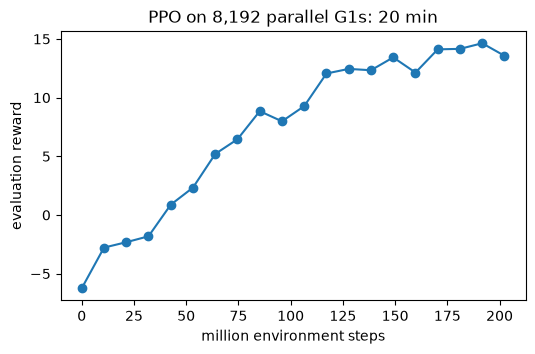

In [2]:
if not os.path.exists(CKPT):
    p = locomotion_params.brax_ppo_config(ENV); params = dict(p); params.pop("network_factory")
    curve, t0 = [], time.time()
    def progress(step, metrics):
        curve.append((step, float(metrics["eval/episode_reward"]), time.time() - t0)); print(f"step {step:>12,}  reward {curve[-1][1]:7.2f}  {curve[-1][2]:5.0f}s")
    cfg = registry.get_default_config(ENV)
    _, prm, _ = ppo.train(environment=registry.load(ENV, config=cfg), eval_env=registry.load(ENV, config=cfg), wrap_env_fn=wrapper.wrap_for_brax_training,
                          progress_fn=progress, randomization_fn=registry.get_domain_randomizer(ENV),
                          network_factory=functools.partial(ppo_networks.make_ppo_networks, **NET_CFG), **params)
    pickle.dump(jax.tree_util.tree_map(np.asarray, prm), open(CKPT, "wb")); np.save("checkpoints/g1_joystick_curve.npy", np.array(curve))
params = pickle.load(open(CKPT, "rb"))
curve = np.load("checkpoints/g1_joystick_curve.npy")
plt.figure(figsize=(6, 3.5)); plt.plot(curve[:, 0] / 1e6, curve[:, 1], "o-")
plt.xlabel("million environment steps"); plt.ylabel("evaluation reward"); plt.title(f"PPO on 8,192 parallel G1s: {curve[-1, 2] / 60:.0f} min"); plt.show()
nets = ppo_networks.make_ppo_networks(env.observation_size, env.action_size, preprocess_observations_fn=running_statistics.normalize, **NET_CFG)
policy = ppo_networks.make_inference_fn(nets)(params, deterministic=True)
hold = lambda obs, key: (jp.zeros(env.action_size), {})     # baseline: every joint holds the default standing pose (joint PD)

## 2. Rollouts as one compiled call
A whole episode is a `lax.scan` on the GPU; `vmap` runs many random seeds at once. Commands are `[vx, vy, yaw rate]`;
a push adds a sudden velocity to the pelvis (like a shove).

In [3]:
def make_rollout(pol):
    def episode(key, commands, pushes):
        state = env.reset(key)
        def body(state, inp):
            cmd, push = inp
            state = state.replace(info={**state.info, "command": cmd})
            state = state.replace(data=state.data.replace(qvel=state.data.qvel.at[:3].add(push)))
            act, _ = pol(state.obs, key)
            state = env.step(state, act)
            return state, (state.data.qpos, env.get_local_linvel(state.data, "pelvis")[:2], state.done)
        return jax.lax.scan(body, state, (commands, pushes))[1]
    return jax.jit(episode), jax.jit(jax.vmap(episode, in_axes=(0, None, None)))

def schedule(segments):
    return jp.concatenate([jp.tile(jp.array(c, dtype=jp.float32), (n, 1)) for n, c in segments])

run_rl, run_rl_batch = make_rollout(policy)
run_hold, run_hold_batch = make_rollout(hold)

## 3. Standing still, getting shoved: learned policy vs holding the pose
Command: stand (0 velocity). At t = 2 s the pelvis gets a velocity kick. 16 random seeds per push size and direction.
"Holding the pose" is the joint-PD baseline of S04 42c: no coordination, no stepping. (Kick 0 = no push at all.)

linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5

linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5

... (274 outputs left out)

linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
To disable the 

linesearch iterations limit reached - please increase ls_iterations beyond 5


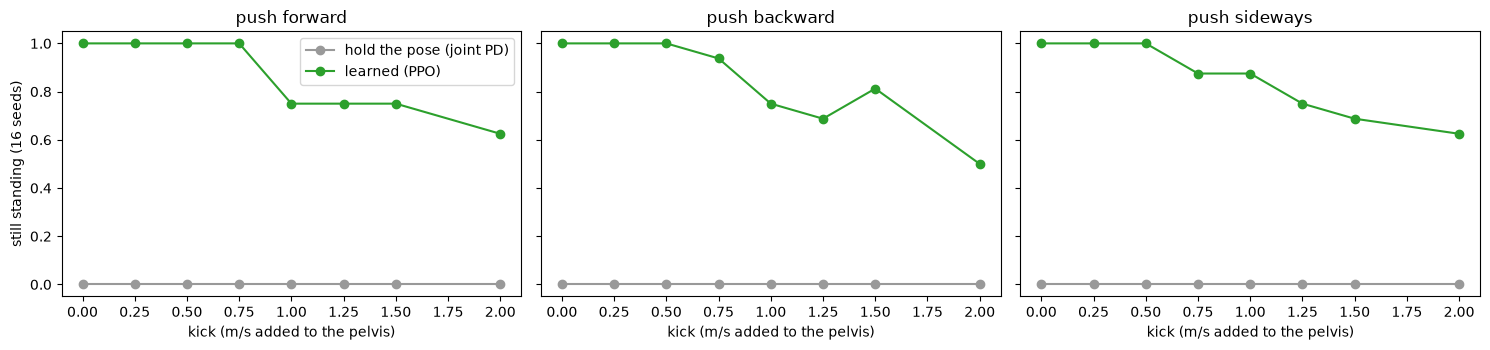

forward   hold the pose (joint PD): 0% 0% 0% 0% 0% 0% 0% 0% | learned (PPO): 100% 100% 100% 100% 75% 75% 75% 62%
backward  hold the pose (joint PD): 0% 0% 0% 0% 0% 0% 0% 0% | learned (PPO): 100% 100% 100% 94% 75% 69% 81% 50%
sideways  hold the pose (joint PD): 0% 0% 0% 0% 0% 0% 0% 0% | learned (PPO): 100% 100% 100% 88% 88% 75% 69% 62%


In [4]:
T, AT = 300, 100                                             # 6 s at 50 Hz; push at 2 s
keys = jax.random.split(jax.random.PRNGKey(0), 16)
stand = schedule([(T, [0.0, 0.0, 0.0])])
kicks = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
dirs = {"forward": (1, 0), "backward": (-1, 0), "sideways": (0, 1)}
surv = {}
t0 = time.time()
for name, (dx, dy) in dirs.items():
    for label, run in [("learned (PPO)", run_rl_batch), ("hold the pose (joint PD)", run_hold_batch)]:
        surv[(name, label)] = []
        for k in kicks:
            push = jp.zeros((T, 3)).at[AT].set(jp.array([dx * k, dy * k, 0.0]))
            surv[(name, label)].append(1.0 - float(np.asarray(run(keys, stand, push)[2]).any(1).mean()))
print(f"{len(dirs) * 2 * len(kicks) * 16} episodes in {time.time() - t0:.0f}s")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a, name in zip(ax, dirs):
    for label, c in [("hold the pose (joint PD)", "#999"), ("learned (PPO)", "tab:green")]:
        a.plot(kicks, surv[(name, label)], "o-", c=c, label=label)
    a.set_title(f"push {name}"); a.set_xlabel("kick (m/s added to the pelvis)")
ax[0].set_ylabel("still standing (16 seeds)"); ax[0].legend(); plt.tight_layout(); plt.show()
for name in dirs:
    print(f"{name:9s} " + " | ".join(f"{label}: " + " ".join(f"{s:.0%}" for s in surv[(name, label)]) for label in ("hold the pose (joint PD)", "learned (PPO)")))

The baseline doesn't even survive **zero** push here: Playground's G1 uses soft joint gains (made for a policy that
keeps moving its joints), and with them, holding a fixed pose doesn't stand. Balance is not a property of the
joints; it's a closed loop through the whole body. The learned policy stands, and recovers from most shoves by
stepping.

## 4. Walking: does it do what the joystick says?

linesearch iterations limit reached - please increase ls_iterations beyond 5


d - please increase iterations beyond 3
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
solver iteratio

ns limit reached - please increase iterations beyond 3
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5


... (11 outputs left out)

linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


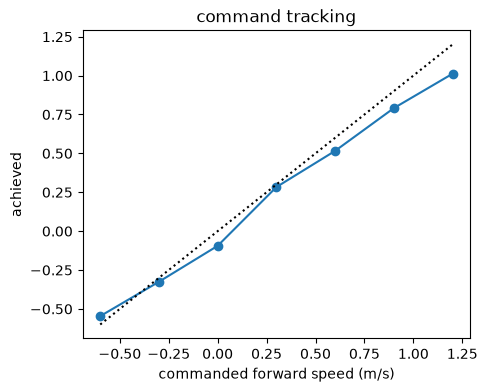

In [5]:
speeds = np.linspace(-0.6, 1.2, 7)
ach = [float(np.asarray(run_rl(jax.random.PRNGKey(1), schedule([(300, [v, 0, 0])]), jp.zeros((300, 3)))[1])[100:, 0].mean()) for v in speeds]
plt.figure(figsize=(5, 4)); plt.plot(speeds, ach, "o-"); plt.plot(speeds, speeds, "k:")
plt.xlabel("commanded forward speed (m/s)"); plt.ylabel("achieved"); plt.title("command tracking"); plt.show()

## 5. Share-ready video: a joystick session with shoves
Walk forward, curve left, side-step, walk back, stop, and take two shoves (one while standing, one while walking).

In [6]:
segs = [(100, [0.0, 0, 0]), (150, [0.8, 0, 0]), (125, [0.5, 0, 0.8]), (100, [0.0, 0.4, 0]), (100, [-0.4, 0, 0]), (150, [0.0, 0, 0])]
cmds = schedule(segs)
pushes = jp.zeros((len(cmds), 3)).at[60].set(jp.array([0.0, 1.0, 0.0])).at[200].set(jp.array([1.0, 0.0, 0.0]))
qpos, vel, done = run_rl(jax.random.PRNGKey(7), cmds, pushes)
qpos, done = np.asarray(qpos), np.asarray(done)
print("fell during the session:", bool(done.any()))
m = env.mj_model; d = mujoco.MjData(m)
m.vis.global_.offwidth, m.vis.global_.offheight = 1280, 720
r = mujoco.Renderer(m, 720, 1280); cam = mujoco.MjvCamera(); cam.distance, cam.elevation = 2.0, -12
labels = ["standing", "walk forward", "curve left", "side-step", "walk back", "stand"]
bounds = np.cumsum([0] + [n for n, _ in segs])
push_steps = {60: "shove sideways", 200: "shove forward"}
frames, look, az = [], None, None
for t, q in enumerate(qpos):
    d.qpos[:] = q; mujoco.mj_forward(m, d)
    p = d.qpos[:3] * [1, 1, 0] + [0, 0, 0.65]; look = p if look is None else 0.9 * look + 0.1 * p
    yaw = np.degrees(np.arctan2(2 * (q[3] * q[6] + q[4] * q[5]), 1 - 2 * (q[5] ** 2 + q[6] ** 2))) + 140
    az = yaw if az is None else az + 0.05 * ((yaw - az + 180) % 360 - 180)
    cam.lookat[:], cam.azimuth = look, az
    r.update_scene(d, cam); img = r.render().copy()
    seg = labels[int(np.searchsorted(bounds, t, side="right")) - 1]
    img = sc.caption(img, f"Unitree G1 · learned locomotion (PPO in MJX) · {seg}", where="top", size=26)
    shove = next((txt for s, txt in push_steps.items() if s <= t < s + 15), None)
    frames.append(sc.badge(img, shove, corner="tr", size=24, color=sc.BAD) if shove else img)
video = sc.title_card("A humanoid that keeps its balance", "PPO on 8,192 parallel G1s · 20 minutes on one GPU\nMuJoCo Playground · Unitree G1", size=(720, 1280), n=75) + frames
show_video(video, fps=int(round(1 / env.dt)), title="53b G1 RL balance HD", width=960)
sc.export(video, "outputs/53b_g1_rl_balance.mp4", fps=int(round(1 / env.dt)))

linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
To disable the p

linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
To disable the

linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5
linesearch iterations limit reached - please increase ls_iterations beyond 5


fell during the session: True


/usr/lib/python3.12/subprocess.py:1885: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


saved outputs/53b_g1_rl_balance.mp4  (11.8 MB)


['outputs/53b_g1_rl_balance.mp4']

## What changed compared with LQR (S04 42c)
- **Stepping.** The learned policy recovers from a shove by taking steps; LQR and joint PD can only lean.
- **No model needed at run time**, but a model (the simulator) was needed for 200M steps of practice.
- **No guarantees.** LQR's stability around its pose is provable; the policy's isn't. That's why S15 wraps learned
  controllers in safety filters.

## Exercises
1. **Ablate the pushes:** retrain with `cfg.push_config.enable = False` (check the config key names with
   `registry.get_default_config(ENV)`) and redo section 3. How much of the robustness came from training with pushes?
2. **Training budget:** train for 50M and 100M steps. Plot push survival against training steps.
3. **Upper body:** command the arms to a reaching pose while the legs keep balance. Where does the policy break?